In [ ]:
import os
import sys

import time
import json
import numpy as np
import matplotlib.pyplot as plt
from gensim.models import KeyedVectors

import utils

print("Loading pre-trained embedding models...")
w2v_model = KeyedVectors.load('word2vec-google-news-300.model', mmap='r')
glove_model = KeyedVectors.load('glove.6B.300d.kv', mmap='r')
ft_model = KeyedVectors.load('wiki-news-300d-1M-subword.kv', mmap='r')
print("All 3 models loaded.")


Loading pre-trained embedding models...


All 3 models loaded.


In [2]:
models = [('Word2Vec', w2v_model), ('GloVe', glove_model), ('FastText', ft_model)]

for name, model in models:
    print(f"\n=================== {name} ===================")
    # Example a: good - bad + excellent
    res_a = model.most_similar(positive=['good', 'excellent'], negative=['bad'], topn=5)
    print(f"a) good - bad + excellent = {res_a[0][0]} (score: {res_a[0][1]:.4f})")
    print("   Top-5:", ", ".join([f"{w} ({s:.3f})" for w, s in res_a]))
    
    # Example b: delivery - late + fast
    res_b = model.most_similar(positive=['delivery', 'fast'], negative=['late'], topn=5)
    print(f"b) delivery - late + fast = {res_b[0][0]} (score: {res_b[0][1]:.4f})")
    print("   Top-5:", ", ".join([f"{w} ({s:.3f})" for w, s in res_b]))



=================== Word2Vec ===================


a) good - bad + excellent = terrific (score: 0.6986)
   Top-5: terrific (0.699), superb (0.644), fantastic (0.641), great (0.632), exceptional (0.589)
b) delivery - late + fast = delievery (score: 0.4610)
   Top-5: delievery (0.461), twitch_muscles (0.429), Delivery (0.425), Eat##Hours.com (0.399), www.BobBruss.com (0.398)

=================== GloVe ===================


a) good - bad + excellent = superb (score: 0.5926)
   Top-5: superb (0.593), terrific (0.572), wonderful (0.532), quality (0.509), great (0.501)
b) delivery - late + fast = faster (score: 0.4703)
   Top-5: faster (0.470), deliveries (0.465), bowler (0.451), slow (0.448), pace (0.444)

=================== FastText ===================


a) good - bad + excellent = superb (score: 0.7591)
   Top-5: superb (0.759), excelent (0.745), excellant (0.737), exellent (0.710), admirable (0.688)
b) delivery - late + fast = super-fast (score: 0.5805)
   Top-5: super-fast (0.581), delivering (0.570), ultra-fast (0.569), fast- (0.566), hyper-fast (0.546)


In [3]:
# Load precomputed experiment results for instant inspection
with open('experiment_results.json', 'r') as f:
    res = json.load(f)

analogy_res = res['analogy_results']
categories = list(analogy_res['Word2Vec']['categories'].keys())

print("-" * 72)
print(f"{'Category':<30} | {'Word2Vec':<10} | {'GloVe':<10} | {'FastText':<10}")
print("-" * 72)
for cat in categories:
    w = analogy_res['Word2Vec']['categories'][cat]['accuracy'] * 100
    g = analogy_res['GloVe']['categories'][cat]['accuracy'] * 100
    f = analogy_res['FastText']['categories'][cat]['accuracy'] * 100
    print(f"{cat:<30} | {w:>8.2f}% | {g:>8.2f}% | {f:>8.2f}%")
print("-" * 72)
ow = analogy_res['Word2Vec']['overall_accuracy'] * 100
og = analogy_res['GloVe']['overall_accuracy'] * 100
of = analogy_res['FastText']['overall_accuracy'] * 100
print(f"{'OVERALL ACCURACY':<30} | {ow:>8.2f}% | {og:>8.2f}% | {of:>8.2f}%")
print("-" * 72)


------------------------------------------------------------------------
Category                       | Word2Vec   | GloVe      | FastText  
------------------------------------------------------------------------
capital-common-countries       |    82.21% |    95.45% |    97.23%
capital-world                  |    81.50% |    95.31% |    96.09%
currency                       |    15.94% |    10.97% |     5.89%
city-in-state                  |    72.76% |    61.09% |    81.23%
family                         |    77.47% |    79.45% |    72.92%
gram1-adjective-to-adverb      |    28.93% |    20.56% |    57.86%
gram2-opposite                 |    32.39% |    22.04% |    55.30%
gram3-comparative              |    89.56% |    87.39% |    94.52%
gram4-superlative              |    67.56% |    58.20% |    53.21%
gram5-present-participle       |    73.48% |    63.73% |    89.87%
gram6-nationality-adjective    |    85.43% |    92.68% |    91.56%
gram7-past-tense               |    66.22% |   

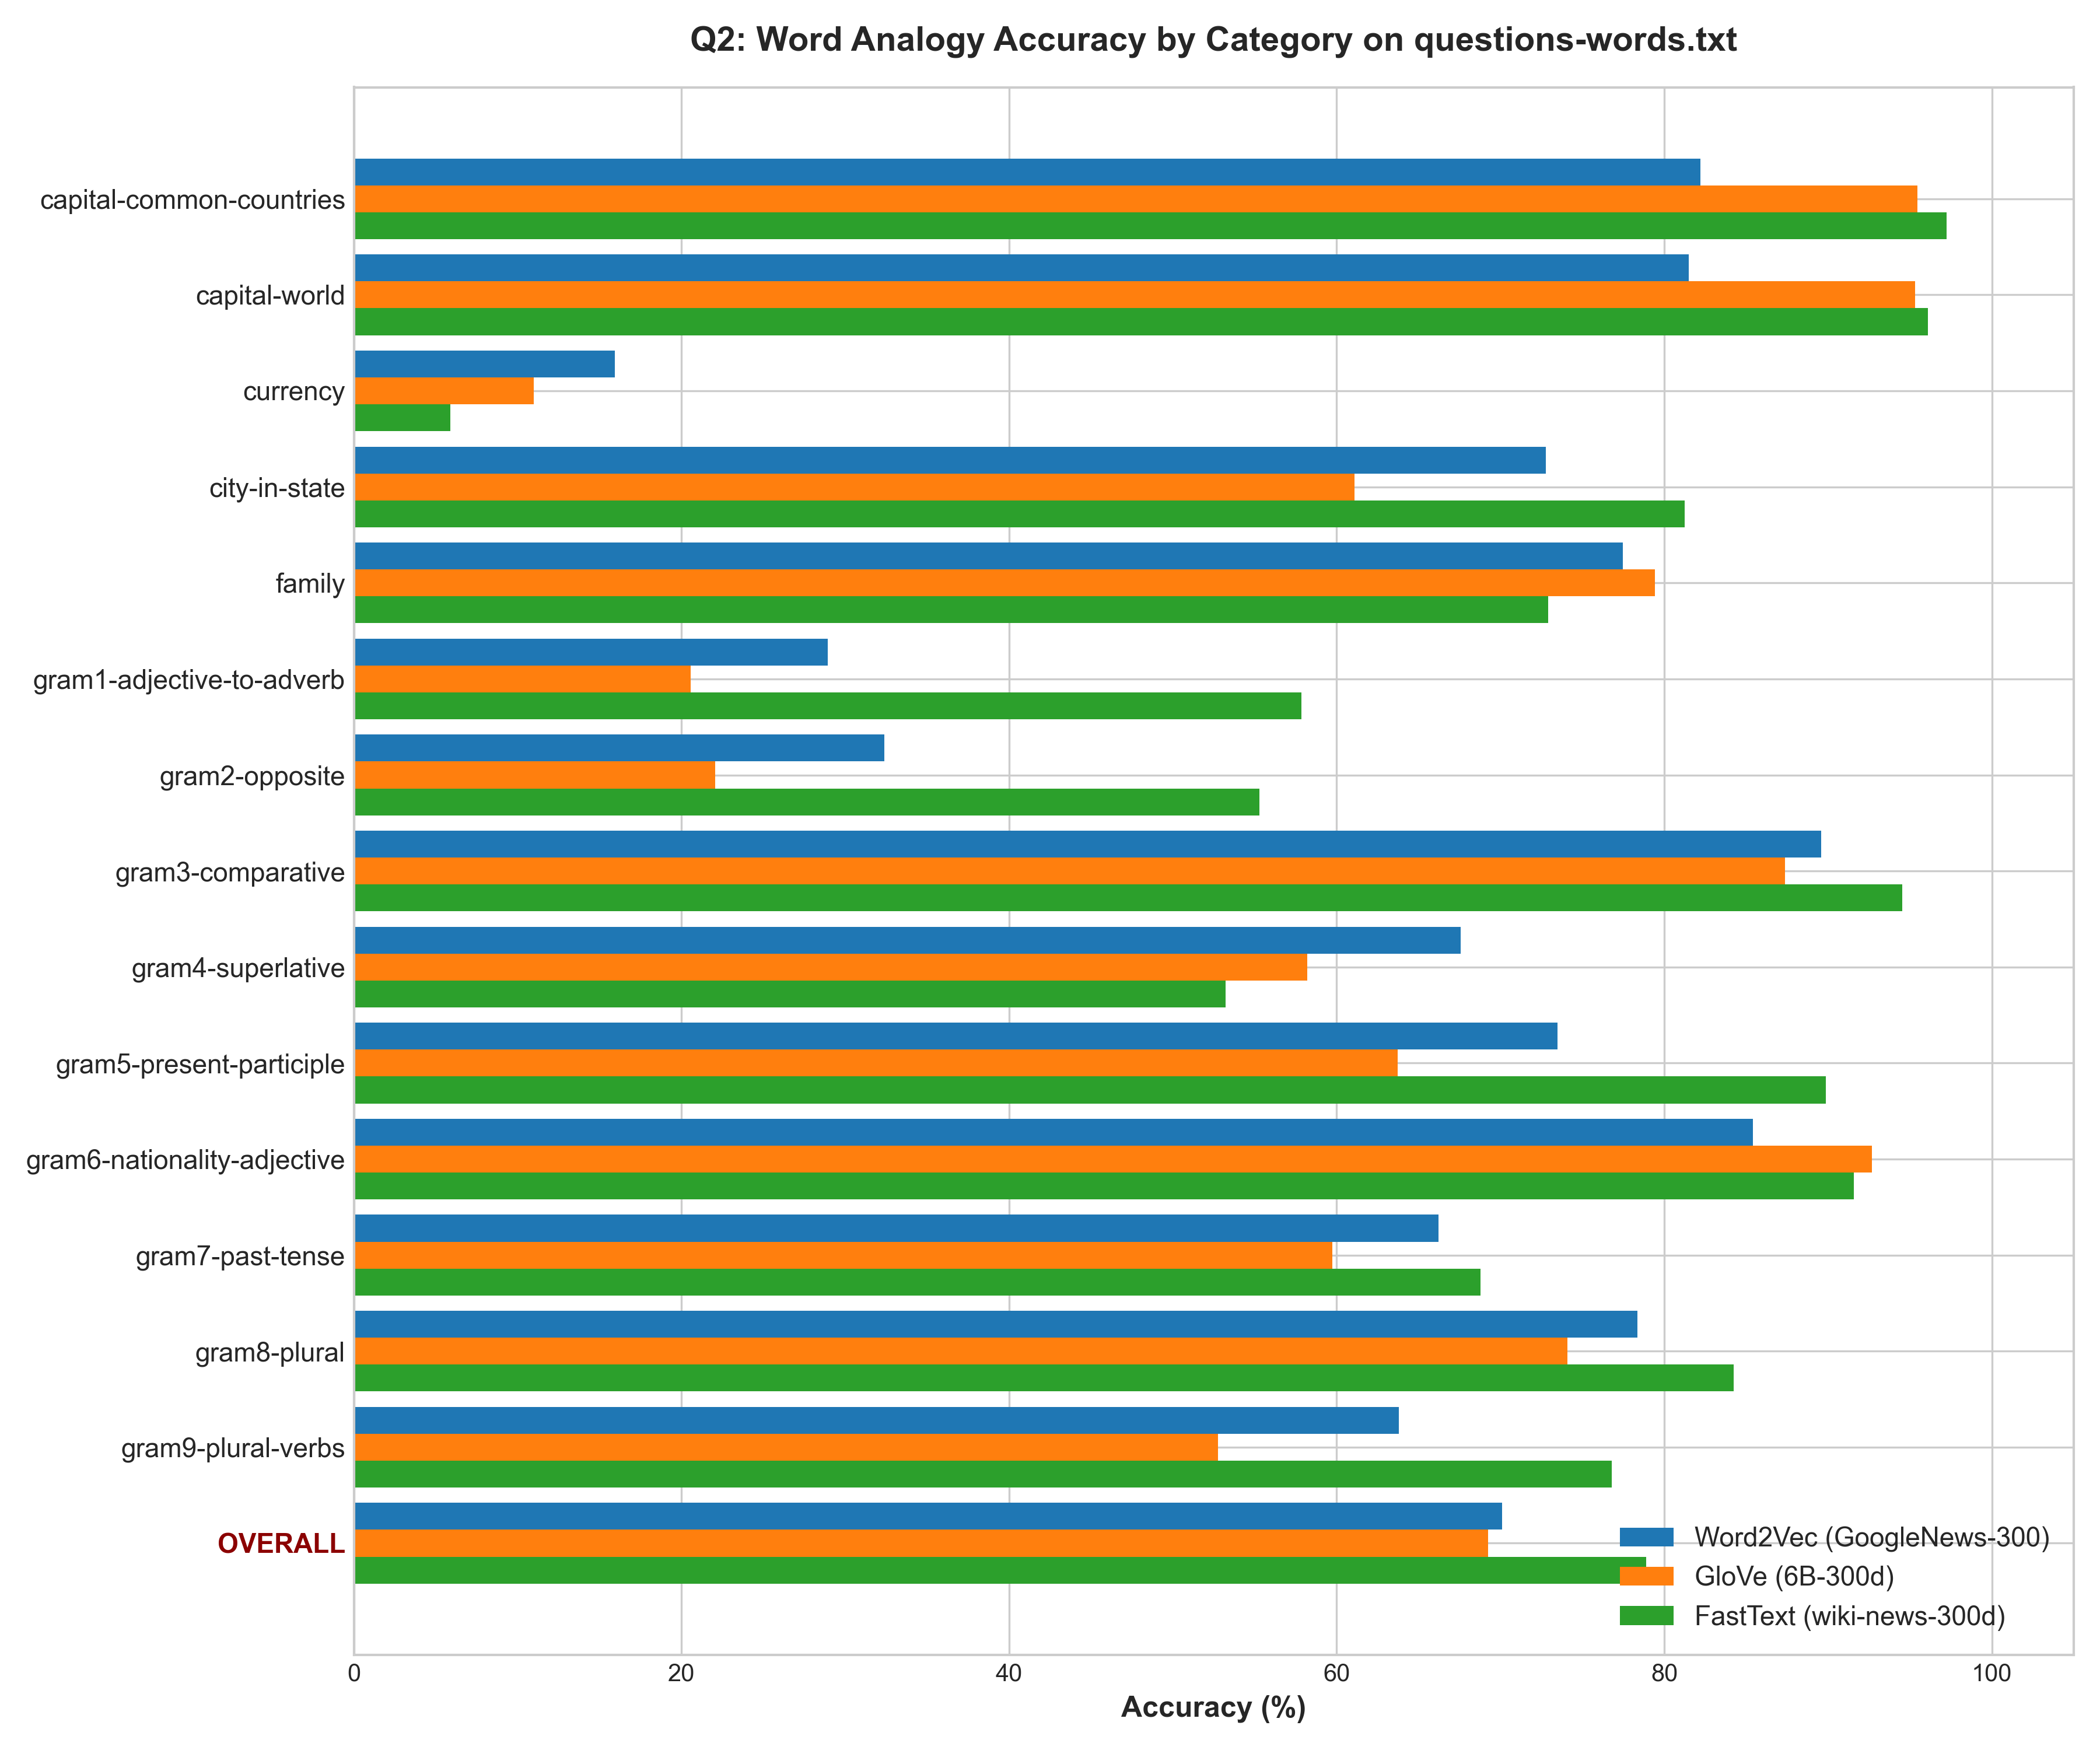

In [4]:
from IPython.display import Image, display
display(Image(filename='analogy_accuracy_comparison.png'))
